# Práctica. Detección de anomalías en el consumo energético con Python

## 1. Planteamiento del problema
Una organización monitorea el consumo eléctrico de un edificio cada hora. El equipo de operación observa incrementos y disminuciones inusuales y necesita identificar registros que merezcan revisión.

El objetivo es localizar observaciones inusuales y aportar evidencia para interpretarlas.

## 2. Objetivo
Aplicar Python para cargar, explorar, visualizar y analizar datos de consumo energético, identificando posibles anomalías mediante un criterio estadístico.

## 3. Bibliotecas
Pandas, NumPy, Matplotlib y SciPy. Si alguna no está instalada, ejecuta en una celda independiente:
```python
%pip install pandas numpy matplotlib scipy
```

## 4. Archivo de trabajo
Coloca `consumo_energetico_practica_01.csv` en la misma carpeta que este notebook. La columna `anomalia_insertada` es una referencia didáctica y se utilizará solo al evaluar los resultados al final.

In [2]:
%pip install pandas numpy matplotlib scipy

  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.7 MB 911.1 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/10.7 MB 1.1 MB/s eta 0:00:09
   --- ------------------------------------ 1.0/10.7 MB 1.1 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/10.7 MB 1.1 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/10.7 MB 1.1 MB/s eta 0:00:09
   ----- ---------------------------------- 1.6/10.7 MB 924.2 kB/s eta 0:00:10
   ----- ---------------------------------- 1.6/10.7 MB 924.2 kB/s eta 0:00:10
   ----- ---------------------------------- 1.6/10.7 MB 924.2 kB/s eta 0:00:10
   ----- ---------------------------------- 1.6/10.7 MB 924.2 kB/s eta 0:00:10
   ------ ------

In [2]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
print(pd.__version__)

3.1.0


In [2]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\mygarcia\AppData\Local\anaconda3\envs\T_MCD\python.exe
3.15.2 | packaged by Anaconda, Inc. | (main, Oct 28 2026, 14:03:59) [MSC v.1942 64 bit (AMD64)]


## Etapa 1. Carga de datos
**Explicación:** Pandas lee el CSV y organiza los registros en un DataFrame. Ejecuta la celda y observa los primeros registros.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

archivo = Path("consumo_energetico_practica_01.csv")
if not archivo.exists():
    raise FileNotFoundError(f"No se encontró {archivo.name}. Coloca el CSV junto al notebook.")
datos = pd.read_csv(archivo, parse_dates=["fecha_hora"])
datos.head()


,fecha_hora,consumo_kwh,temperatura_c,dia_semana,hora,anomalia_insertada
0,2026-09-01 00:00:00,31.35,16.9,Tuesday,0,False
1,2026-09-01 01:00:00,26.67,18.7,Tuesday,1,False
2,2026-09-01 02:00:00,32.78,14.8,Tuesday,2,False
3,2026-09-01 03:00:00,34.48,16.8,Tuesday,3,False
4,2026-09-01 04:00:00,26.98,18.8,Tuesday,4,False


**Preguntas**
1. ¿Cuántos registros contiene el conjunto?
2. ¿Qué representa cada fila?
3. ¿Cuál es la unidad de `consumo_kwh`?

In [9]:
#1
print("Total de registros:", len(datos))

Total de registros: 720


In [10]:
#2
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   fecha_hora          720 non-null    datetime64[us]
 1   consumo_kwh         720 non-null    float64       
 2   temperatura_c       720 non-null    float64       
 3   dia_semana          720 non-null    str           
 4   hora                720 non-null    int64         
 5   anomalia_insertada  720 non-null    bool          
dtypes: bool(1), datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 29.0 KB


In [11]:
#3
print(datos["consumo_kwh"].describe())

count    720.000000
mean      41.756486
std       17.697078
min        6.690000
25%       29.127500
50%       35.980000
75%       60.267500
max       71.970000
Name: consumo_kwh, dtype: float64


In [8]:
datos[100:121]

,fecha_hora,consumo_kwh,temperatura_c,dia_semana,hora,anomalia_insertada
100,2026-09-05 04:00:00,14.01,19.4,Saturday,4,False
101,2026-09-05 05:00:00,21.66,23.3,Saturday,5,False
102,2026-09-05 06:00:00,19.01,21.5,Saturday,6,False
103,2026-09-05 07:00:00,25.36,21.8,Saturday,7,False
104,2026-09-05 08:00:00,22.86,23.6,Saturday,8,False
105,2026-09-05 09:00:00,27.84,27.3,Saturday,9,False
106,2026-09-05 10:00:00,27.74,28.2,Saturday,10,False
107,2026-09-05 11:00:00,31.44,28.6,Saturday,11,False
108,2026-09-05 12:00:00,36.31,30.6,Saturday,12,False
109,2026-09-05 13:00:00,28.47,25.3,Saturday,13,False


## Etapa 2. Exploración y calidad
**Explicación:** antes de analizar, revisa dimensiones, tipos, faltantes, duplicados y estadísticas descriptivas.

In [12]:
print("Dimensiones:", datos.shape)
print("\nTipos de datos:\n", datos.dtypes)
print("\nValores faltantes:\n", datos.isna().sum())
print("\nFilas duplicadas:", datos.duplicated().sum())
display(datos[["consumo_kwh", "temperatura_c"]].describe())


Dimensiones: (720, 6)

Tipos de datos:
 fecha_hora            datetime64[us]
consumo_kwh                  float64
temperatura_c                float64
dia_semana                       str
hora                           int64
anomalia_insertada              bool
dtype: object

Valores faltantes:
 fecha_hora            0
consumo_kwh           0
temperatura_c         0
dia_semana            0
hora                  0
anomalia_insertada    0
dtype: int64

Filas duplicadas: 0


,consumo_kwh,temperatura_c
count,720.000000,720.000000
mean,41.756486,22.999861
std,17.697078,4.404737
min,6.690000,13.700000
25%,29.127500,19.100000
50%,35.980000,23.000000
75%,60.267500,27.000000
max,71.970000,31.400000


**Preguntas**
1. ¿Hay valores faltantes o duplicados?
2. ¿Qué diferencia observas entre media y mediana?
3. ¿Qué representa la desviación estándar?

## Etapa 3. Visualización temporal
**Explicación:** una gráfica temporal permite observar picos, caídas y patrones. 

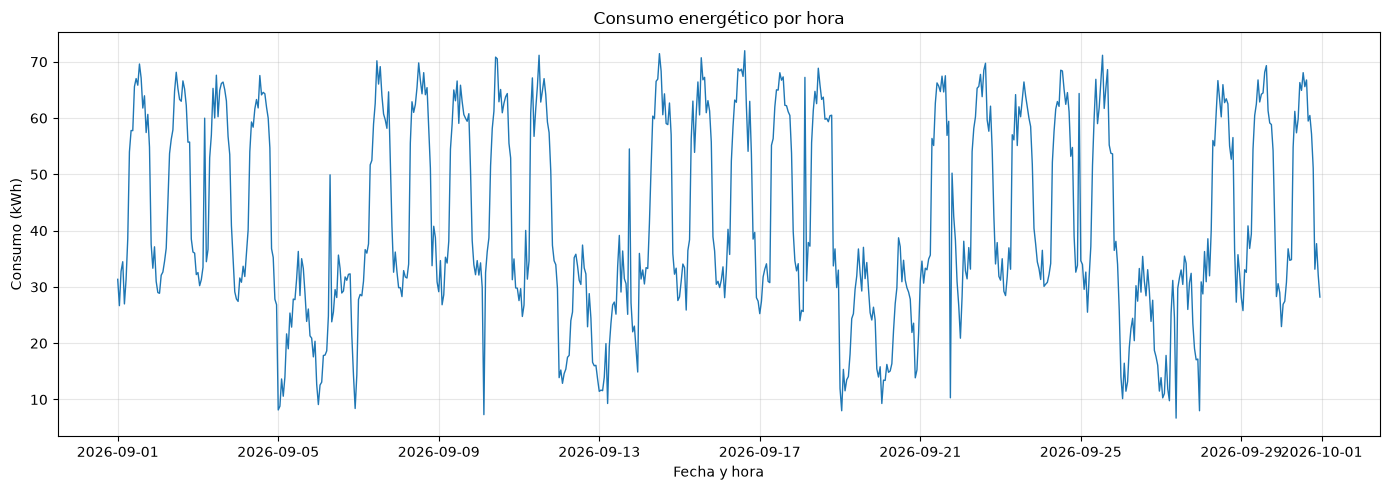

In [13]:
plt.figure(figsize=(14, 5))
plt.plot(datos["fecha_hora"], datos["consumo_kwh"], linewidth=1)
plt.title("Consumo energético por hora")
plt.xlabel("Fecha y hora")
plt.ylabel("Consumo (kWh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Preguntas**
1. ¿Observas picos o caídas abruptas?
2. ¿Se distingue algún patrón temporal?
3. ¿Qué información adicional permitiría saber si un pico es legítimo?

## Etapa 4. Detección con puntuación z
**Explicación:** la puntuación z mide cuántas desviaciones estándar separan una observación de la media:
\[
z_i = \frac{x_i - \bar{x}}{s}
\]
Usaremos `|z| > 3` como umbral inicial. Es convencional, no universal. Una puntuación global puede ignorar patrones por hora o día.

**Actividad:** calcula la puntuación z y crea la columna `anomalia_z`.

In [24]:
consumo = datos["consumo_kwh"].to_numpy()
datos["z_score"] = stats.zscore(consumo, nan_policy="omit")
datos["anomalia_z"] = datos["z_score"].abs() > 1.5

print("Registros señalados:", int(datos["anomalia_z"].sum()))
display(datos.loc[datos["anomalia_z"], ["fecha_hora", "consumo_kwh", "z_score"]])


Registros señalados: 70


,fecha_hora,consumo_kwh,z_score
13,2026-09-01 13:00:00,69.61,1.574999
96,2026-09-05 00:00:00,8.14,-1.900871
97,2026-09-05 01:00:00,8.81,-1.862985
98,2026-09-05 02:00:00,13.65,-1.589303
99,2026-09-05 03:00:00,10.58,-1.762899
...,...,...,...
628,2026-09-27 04:00:00,11.89,-1.688824
629,2026-09-27 05:00:00,9.78,-1.808135
633,2026-09-27 09:00:00,6.69,-1.982862
647,2026-09-27 23:00:00,8.00,-1.908787


In [25]:
print("Z-score mínimo:", datos["z_score"].min())
print("Z-score máximo:", datos["z_score"].max())
print("Valores faltantes:", datos["consumo_kwh"].isna().sum())
print("Anomalías detectadas:", datos["anomalia_z"].sum())

Z-score mínimo: -1.982861967867352
Z-score máximo: 1.7084468462589142
Valores faltantes: 0
Anomalías detectadas: 70


**Preguntas**
1. ¿Cuántos registros se señalaron?
2. ¿Hay consumos inusualmente altos y bajos?
3. ¿Por qué una puntuación global podría no ser adecuada para todos los horarios?

## Etapa 5. Visualización de las alertas
**Explicación:** superponer los puntos señalados sobre la serie temporal ayuda a revisar si están aislados o siguen una tendencia. Son candidatos a investigación para fallas confirmadas.

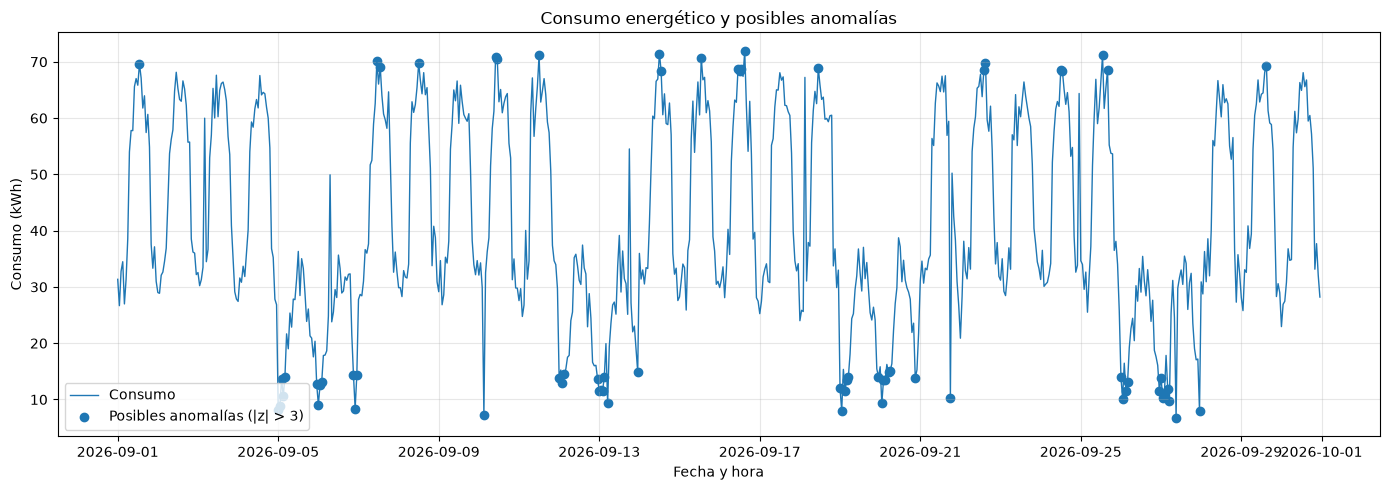

In [26]:
plt.figure(figsize=(14, 5))
plt.plot(datos["fecha_hora"], datos["consumo_kwh"], label="Consumo", linewidth=1)
posibles = datos["anomalia_z"]
plt.scatter(datos.loc[posibles, "fecha_hora"], datos.loc[posibles, "consumo_kwh"],
            label="Posibles anomalías (|z| > 3)", marker="o")
plt.title("Consumo energético y posibles anomalías")
plt.xlabel("Fecha y hora")
plt.ylabel("Consumo (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:
print(datos.columns.tolist())

['fecha_hora', 'consumo_kwh', 'temperatura_c', 'dia_semana', 'hora', 'anomalia_insertada', 'z_score', 'anomalia_z']


In [27]:
print("Anomalías insertadas:")
print(datos["anomalia_insertada"].value_counts())

print("\nAnomalías detectadas por Z-score:")
print(datos["anomalia_z"].sum())

Anomalías insertadas:
anomalia_insertada
False    712
True       8
Name: count, dtype: int64

Anomalías detectadas por Z-score:
70


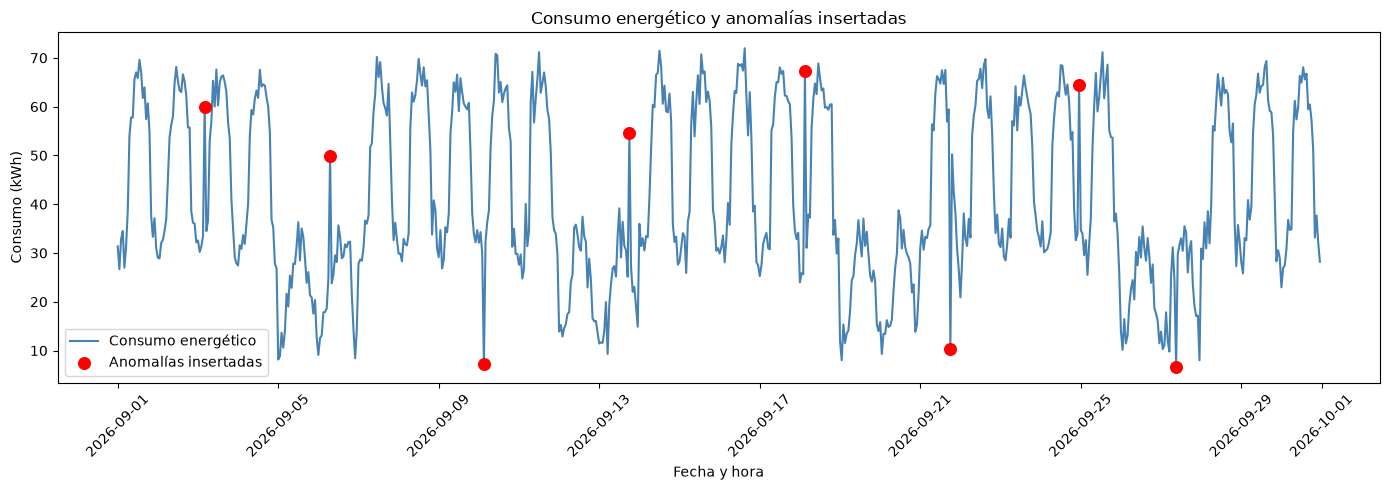

In [28]:
insertadas = datos[datos["anomalia_insertada"] == 1]

plt.figure(figsize=(14, 5))
plt.plot(
    datos["fecha_hora"],
    datos["consumo_kwh"],
    color="steelblue",
    label="Consumo energético"
)

plt.scatter(
    insertadas["fecha_hora"],
    insertadas["consumo_kwh"],
    color="red",
    s=70,
    label="Anomalías insertadas",
    zorder=3
)

plt.xlabel("Fecha y hora")
plt.ylabel("Consumo (kWh)")
plt.title("Consumo energético y anomalías insertadas")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Etapa 6. Evaluación con la referencia didáctica
**Explicación:** como el conjunto es simulado, hay una columna que indica qué anomalías se insertaron. En datos reales esta etiqueta normalmente no estaría disponible. Se utiliza solo para comparar el detector con la referencia del ejercicio.

- **VP:** anomalía insertada y detectada.
- **FP:** registro normal marcado como anomalía.
- **FN:** anomalía insertada no detectada.
- **Precisión:** proporción de alertas que corresponden a anomalías insertadas.
- **Exhaustividad (recall):** proporción de anomalías insertadas que se detectaron.

In [29]:
referencia = datos["anomalia_insertada"].astype(bool)
deteccion = datos["anomalia_z"]
vp = int((referencia & deteccion).sum())
fp = int((~referencia & deteccion).sum())
fn = int((referencia & ~deteccion).sum())
vn = int((~referencia & ~deteccion).sum())
precision = vp / (vp + fp) if (vp + fp) else 0
recall = vp / (vp + fn) if (vp + fn) else 0
print(f"Verdaderos positivos (VP): {vp}")
print(f"Falsos positivos (FP): {fp}")
print(f"Falsos negativos (FN): {fn}")
print(f"Verdaderos negativos (VN): {vn}")
print(f"Precisión: {precision:.3f}")
print(f"Exhaustividad (recall): {recall:.3f}")


Verdaderos positivos (VP): 3
Falsos positivos (FP): 67
Falsos negativos (FN): 5
Verdaderos negativos (VN): 645
Precisión: 0.043
Exhaustividad (recall): 0.375


In [30]:
# Probar un umbral más bajo
umbral = 1.5

datos["anomalia_z_reto"] = datos["z_score"].abs() > umbral

print("Umbral utilizado:", umbral)
print("Alertas detectadas:", datos["anomalia_z_reto"].sum())


Umbral utilizado: 1.5
Alertas detectadas: 70


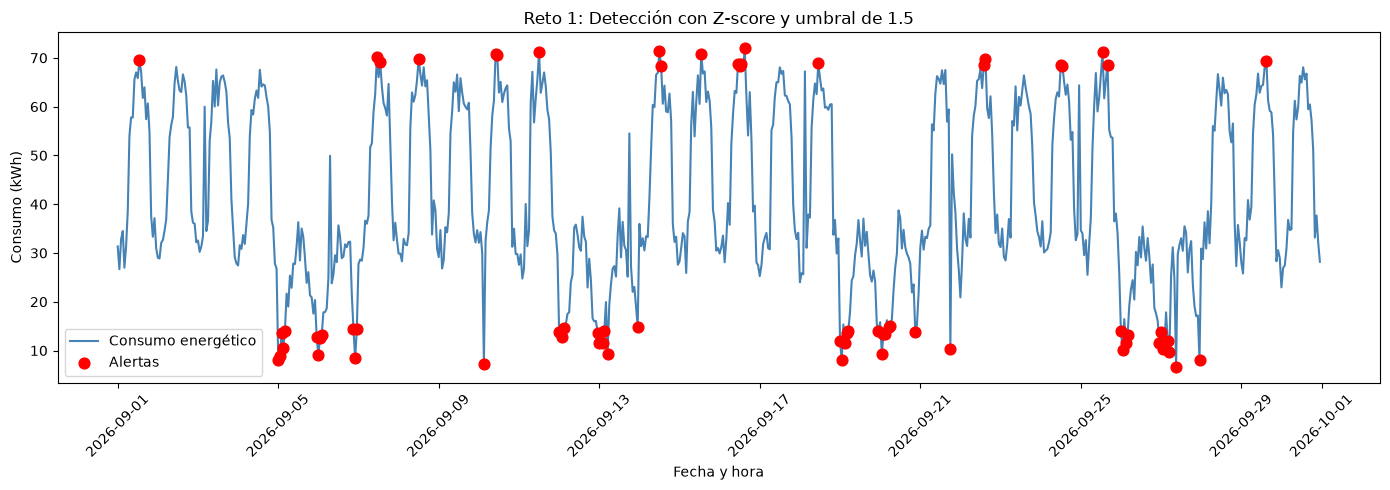

In [31]:

alertas = datos[datos["anomalia_z_reto"]]

plt.figure(figsize=(14, 5))
plt.plot(datos["fecha_hora"], datos["consumo_kwh"],
         label="Consumo energético", color="steelblue")

plt.scatter(alertas["fecha_hora"], alertas["consumo_kwh"],
            color="red", label="Alertas", s=60, zorder=3)

plt.xlabel("Fecha y hora")
plt.ylabel("Consumo (kWh)")
plt.title("Reto 1: Detección con Z-score y umbral de 1.5")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
